In [ ]:
%pip install puremacro


# Bloques de comercio flexible y un equilibrio de referencia

**¿Cómo cambian las decisiones a precios dados la sustitución de factores, la demanda de subsistencia y los márgenes variables, y quién soporta un arancel en un pequeño equilibrio de referencia?**

Todas las cifras provienen de una tabla balanceada a mano con dos países y dos sectores, en unidades de valor ilustrativas; los códigos A, B, FOOD y MANU no se refieren a economías observadas. Las secciones 1-3 evalúan los bloques de costos, demanda y precios de la biblioteca a precios dados. Las secciones 4-6 resuelven un equilibrio arancelario, muestran cuánto depende su respuesta de una elasticidad y lo resuelven de nuevo con los bloques flexibles por dos vías distintas.

## El método en matemáticas

Los gorros indican razones respecto de la referencia: $\hat r$ y $\hat w$ son la renta del capital y el salario, $\alpha$ es la participación del capital en el valor agregado y $\rho$ la elasticidad capital-trabajo. Costo unitario del valor agregado con elasticidad de sustitución constante (CES) y demanda condicional de factores:
$$\hat c_{VA}=\big[\alpha\hat r^{1-\rho}+(1-\alpha)\hat w^{1-\rho}\big]^{1/(1-\rho)},\qquad \frac{K/L}{K_0/L_0}=\Big(\frac{\hat w}{\hat r}\Big)^{\rho}.$$
La demanda de los hogares es un sistema de gasto lineal (LES; Geary 1950, Stone 1954) con una cantidad de subsistencia que escala con el ingreso: $c_s=\bar c_s(u)+b_s\big[m-\sum_kP_k\bar c_k(u)\big]^+/P_s$ con $\bar c_s(u)=\gamma_s c_{s0}\,g(u)$ y $g(u)=\tanh(3u)/\tanh(3)$. Aquí $m$ es el presupuesto del hogar (gasto en bienes neto de impuestos al uso final), $u$ el presupuesto relativo a su referencia, $P_s$ los precios compuestos, $c_{s0}$ las cantidades de referencia, $\gamma_s$ la participación de subsistencia, $b_s$ las participaciones presupuestarias marginales calibradas y $[\cdot]^+$ el recorte en cero de la biblioteca.
Márgenes de Cournot (Atkeson y Burstein 2008) con participación de mercado de destino $\omega$: $\mathcal M(\omega)=\sigma_j/[\sigma_j-1+(1-\sigma_j/\theta_j)\,\omega]$, con la elasticidad dentro del sector $\sigma_j$ mayor que la elasticidad entre sectores $\theta_j$, acotados a $[1,5]$.
El equilibrio de referencia resuelve $\|R(x)\|_\infty\le\epsilon$ para precios, producciones, precios de factores y transferencias. El productor $j$ compra insumos de un único nido CES sobre todos los países-sector de origen $i$, $Z_{ij}=a_{ij}\,y_j\,\big(P_j/(p_i\tau_{ij})\big)^{\sigma}$. Cuando A impone el arancel $t$, la parte que soportan los productores de B es $\iota=-\Delta\ln p_B/\ln(1+t)$, con el precio de los alimentos de A como numerario, y los términos de intercambio de un país son su valor unitario de exportación sobre su valor unitario de importación a precios de productor.

## Intuición

**Intuición.** Un $\rho$ mayor significa que las empresas sustituyen trabajo por capital con más facilidad cuando los salarios suben frente a las rentas. Una cantidad de subsistencia que escala con el ingreso convierte a los alimentos en un bien necesario, de modo que su participación presupuestaria cae al subir el ingreso. Cuando $\sigma_j>\theta_j$, una empresa con mayor participación en su mercado de destino enfrenta una demanda menos elástica y cobra un margen mayor. Estos tres bloques se evalúan a precios dados y no cierran ningún mercado. En el equilibrio, el arancel de A reduce sus compras a B; con el ahorro externo fijo, los precios y salarios de B deben ajustarse hasta que el comercio vuelva a equilibrarse. Las canastas de uso final tienen coeficientes fijos, así que los compradores de A dejan los bienes de B sobre todo a través de los insumos intermedios, a una velocidad que fija $\sigma$. Si sustituyen con facilidad, una baja de los precios de B recupera ventas y B absorbe el arancel. Si sustituyen demasiado poco, una baja de precios reduce los ingresos por exportaciones de B y sus precios deben subir: es una condición de tipo Marshall-Lerner, en cuya frontera la respuesta del equilibrio no está acotada.

## Código resuelto

Los países A y B producen alimentos (FOOD) y manufacturas (MANU).

In [1]:
from pathlib import Path
from dataclasses import replace
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()
colors, dashes = _nbstyle.palette(3), _nbstyle.styles(3)
from puremacro.trade import (calibrate_trade_model, compute_equilibrium_residuals,
                             solve_flexible_trade_equilibrium, solve_trade_equilibrium)
from puremacro.trade.ces_newton import NestedCESTechnology, solve_ces_block_newton
from puremacro.trade.flexible import (
    FlexibleTechnologyConfig, FlexiblePreferenceConfig,
    compute_nested_ces_costs, compute_nested_factor_demands,
    compute_stone_geary_final_demand, compute_atkeson_burstein_markups,
    smooth_subsistence_scaling,
)

# Rows/columns of the intermediate block: A-food, A-manufactures, B-food, B-manufactures.
Z = np.array([[10., 15., 5., 5.], [15., 20., 10., 10.],
              [5., 5., 12., 18.], [10., 10., 18., 22.]])
output0 = np.array([100., 150., 120., 180.])
# Three final uses per country (A's, then B's); both sectors of a country share one final-use mix.
final_weights = np.array([[.50, .25, .05, .10, .08, .02]] * 2 +
                         [[.10, .08, .02, .50, .25, .05]] * 2)
F = (output0 - Z.sum(axis=1))[:, None] * final_weights
production_tax = .05 * output0  # 5% of output revenue
factor_income = output0 - Z.sum(axis=0) - production_tax
labor_share = np.array([.70, .40, .60, .30])
# Row order read by calibrate_trade_model: transactions, taxes (production, then 2% on final
# uses), labour income, capital income.
table = np.vstack([np.hstack([Z, F]),
    np.r_[production_tax, .02 * F.sum(axis=0)],
    np.r_[labor_share * factor_income, np.zeros(6)],
    np.r_[(1 - labor_share) * factor_income, np.zeros(6)]])
np.testing.assert_allclose(table[:4].sum(axis=1), table[:, :4].sum(axis=0))  # sales = costs
calib = calibrate_trade_model(table, ns=2, nc=2, nfd=3,
    country_codes=["A", "B"], sector_codes=["FOOD", "MANU"])
calib = replace(calib, metadata={**calib.metadata, "is_synthetic": True,
    "source": "hand-balanced teaching table", "unit": "illustrative value units"})
print({key: calib.metadata[key] for key in ("source", "unit", "is_synthetic")})

{'source': 'hand-balanced teaching table', 'unit': 'illustrative value units', 'is_synthetic': True}


### 1. Sustitución condicional de factores

Mantenemos fijos las rentas del capital, los precios de los insumos y la producción, y variamos el salario relativo a la renta. Las curvas muestran el capital por trabajador en las manufacturas de A; el assert comprueba la ley de potencias en todos los sectores y países.

rho = 0.7: capital per worker at w/r = 1.2 is 1.136 x baseline
rho = 1.0: capital per worker at w/r = 1.2 is 1.200 x baseline
rho = 1.4: capital per worker at w/r = 1.2 is 1.291 x baseline


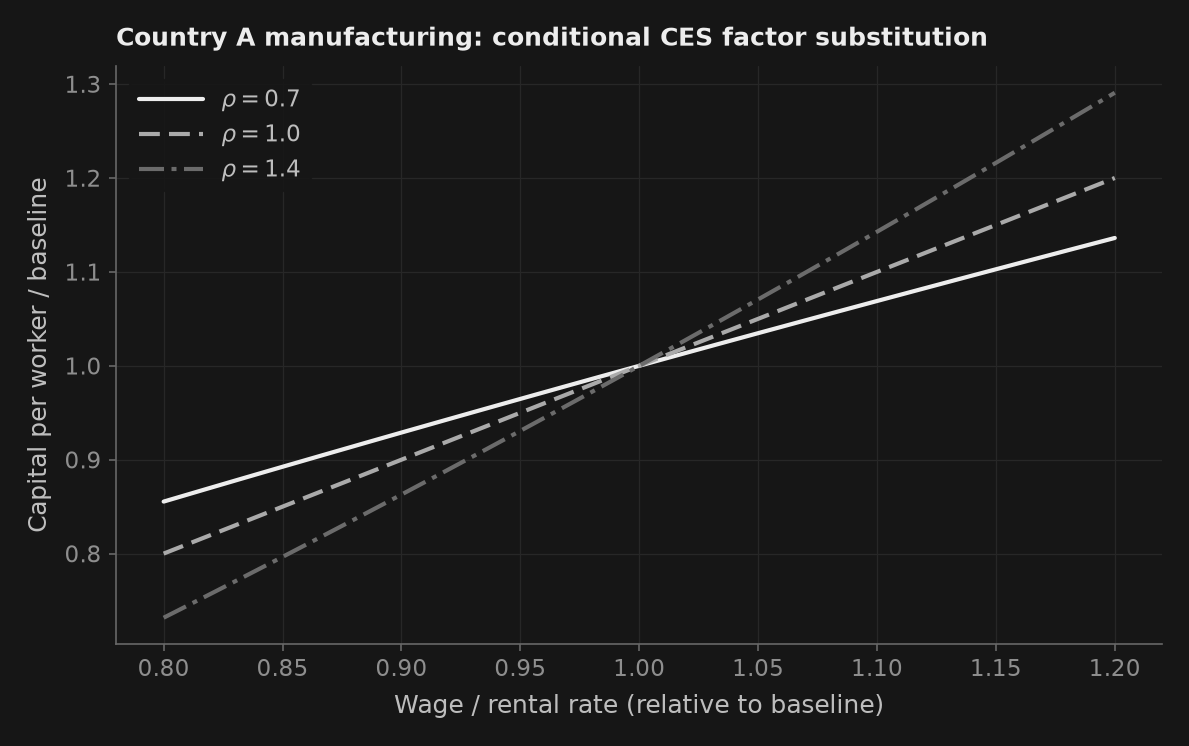

In [2]:
ones = np.ones((1, calib.n_sectors, calib.n_countries))  # unit goods prices
factor_ones = np.ones((1, 1, calib.n_countries))  # unit factor prices
# No tariffs; axes are (origin country-sector, using sector, destination country).
tau_ones = np.ones((calib.n_sectors * calib.n_countries, calib.n_sectors, calib.n_countries))
wage_ratios = np.linspace(.8, 1.2, 25)
elasticities = (.7, 1., 1.4)
fig, ax = plt.subplots(figsize=(9, 5))
for rho, color, dash in zip(elasticities, colors, dashes):
    tech = FlexibleTechnologyConfig(rho_va=rho, sigma_y=.2)

    def capital_per_worker(wage_ratio):
        # Only the wage moves: rental rates, intermediate prices and output stay at the benchmark.
        wages = factor_ones * wage_ratio
        c_va, c_y = compute_nested_ces_costs(r=factor_ones, w=wages, P_M=ones, calib=calib, tech_cfg=tech)
        labor, capital, _ = compute_nested_factor_demands(
            calib.ytot, r=factor_ones, w=wages, P_M=ones, c_va=c_va, c_y=c_y, p=ones,
            tau=tau_ones, calib=calib, tech_cfg=tech)
        return capital / labor

    kl0 = capital_per_worker(1.)
    ratios = np.array([capital_per_worker(x) / kl0 for x in wage_ratios])
    # Every sector and country obeys (K/L)/(K0/L0) = (w/r)^rho, whatever its capital share or sigma_y.
    np.testing.assert_allclose(ratios, np.broadcast_to(wage_ratios[:, None, None, None] ** rho, ratios.shape),
                               rtol=1e-10)
    print(f"rho = {rho:.1f}: capital per worker at w/r = {wage_ratios[-1]:.1f} is "
          f"{ratios[-1, 0, 1, 0]:.3f} x baseline")
    ax.plot(wage_ratios, ratios[:, 0, 1, 0], color=color, linestyle=dash, label=rf"$\rho = {rho:.1f}$")
ax.set(xlabel="Wage / rental rate (relative to baseline)", ylabel="Capital per worker / baseline",
       title="Country A manufacturing: conditional CES factor substitution")
ax.legend()

### 2. Demanda a precios fijos

Comparamos subsistencia nula con una participación de subsistencia de alimentos $\gamma=0.30$: el 30% de la cantidad de alimentos de referencia, escalado por $g(u)$, forma el componente de subsistencia; no es el 30% del ingreso. Como $g(u)>u$ para $0<u<1$, el gasto de subsistencia cae más despacio que el ingreso. Si llegara a superar el presupuesto, la biblioteca recortaría en cero el ingreso supernumerario y devolvería una canasta que gasta de más, con un `RuntimeWarning`; a precios unitarios eso solo puede ocurrir a algún ingreso si $\sum_s\gamma_s s_{s0}$ (participaciones presupuestarias de referencia $s_{s0}$) supera $\tanh(3)/3$. La celda imprime esa suma y la razón entre el gasto de subsistencia y el presupuesto en la cuadrícula, y comprueba que se agote el presupuesto. Esta regla escalada por el ingreso no se deriva de una función de utilidad (su matriz de Slutsky es asimétrica; véase [docs/es/trade_household.md](../docs/es/trade_household.md)), por lo que da curvas de Engel pero ninguna medida de bienestar.

A's benchmark food share s0 = 0.405; gamma * s0 = 0.121 against tanh(3)/3 = 0.332
Subsistence spending / budget: 0.068 to 0.193 on the grid, 0.366 in the limit of a zero budget
Zero subsistence: food share 40.5% at budget x0.6, 40.5% at x1.8
Food subsistence share 0.30: food share 45.3% at budget x0.6, 36.9% at x1.8


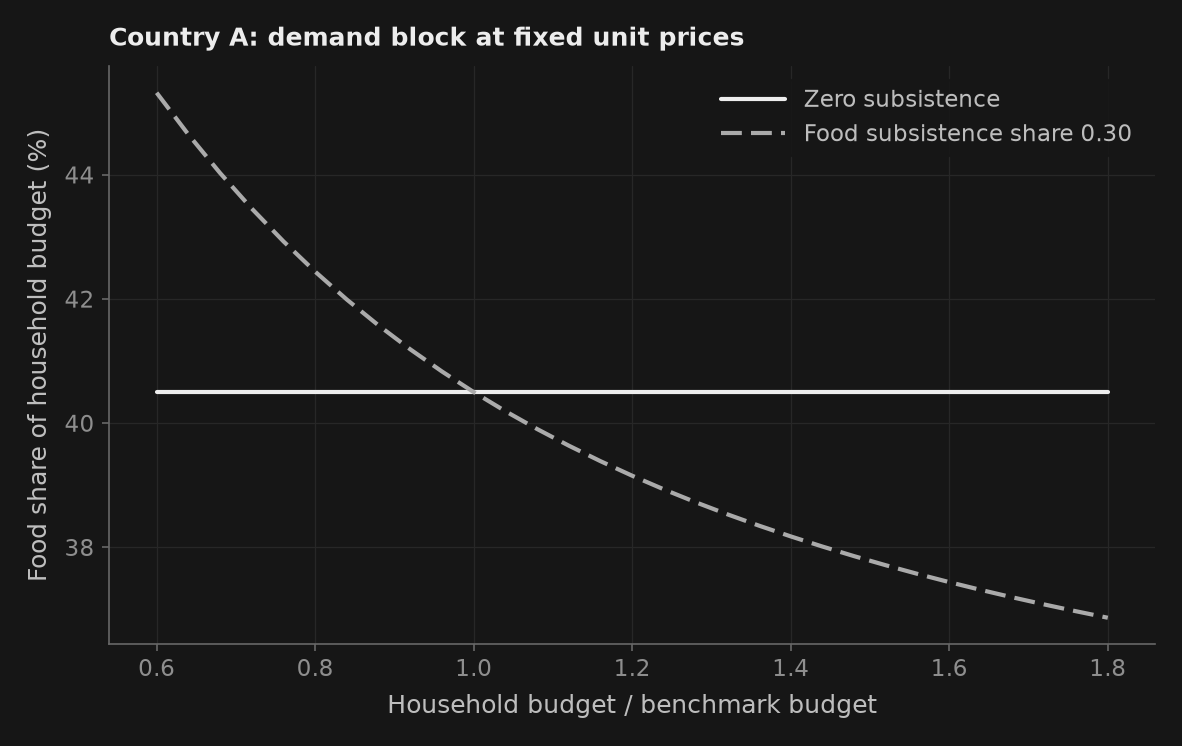

In [3]:
# Household budget: final use 0's spending on goods net of final-use taxes (columns 0 and 3 of F).
budget0 = F[:, [0, 3]].sum(axis=0).reshape(1, 1, 2)
budget_ratios = np.linspace(.6, 1.8, 31)
gamma_food = .30
preferences = {"Zero subsistence": FlexiblePreferenceConfig(),
               f"Food subsistence share {gamma_food:.2f}":
                   FlexiblePreferenceConfig(subsistence_shares={"FOOD": gamma_food})}
# Benchmark food quantity of country A (unit prices, so quantity = spending).
food0 = compute_stone_geary_final_demand(budget0, ones, calib, FlexiblePreferenceConfig())[0, 0, 0]
food_share0 = food0 / budget0[0, 0, 0]
# Subsistence spending over the budget at budget ratio u: gamma * s0 * g(u) / u.
subsistence_ratio = gamma_food * food_share0 * smooth_subsistence_scaling(budget_ratios) / budget_ratios
assert subsistence_ratio.max() < 1  # the clip at zero never binds on this grid
print(f"A's benchmark food share s0 = {food_share0:.3f}; gamma * s0 = {gamma_food * food_share0:.3f} "
      f"against tanh(3)/3 = {np.tanh(3) / 3:.3f}")
print(f"Subsistence spending / budget: {subsistence_ratio.min():.3f} to {subsistence_ratio.max():.3f} "
      f"on the grid, {gamma_food * food_share0 * 3 / np.tanh(3):.3f} in the limit of a zero budget")
fig, ax = plt.subplots(figsize=(9, 5))
for (label, pref), color, dash in zip(preferences.items(), colors, dashes):
    food_shares = []
    for budget_ratio in budget_ratios:
        budget = budget_ratio * budget0
        demand = compute_stone_geary_final_demand(budget, ones, calib, pref)
        np.testing.assert_allclose(demand.sum(axis=1, keepdims=True), budget, rtol=1e-10)
        food_shares.append(100 * demand[0, 0, 0] / budget[0, 0, 0])
    print(f"{label}: food share {food_shares[0]:.1f}% at budget x{budget_ratios[0]:.1f}, "
          f"{food_shares[-1]:.1f}% at x{budget_ratios[-1]:.1f}")
    ax.plot(budget_ratios, food_shares, color=color, linestyle=dash, label=label)
    if pref.subsistence_shares:
        assert food_shares[0] > food_shares[-1]  # food behaves as a necessity
ax.set(xlabel="Household budget / benchmark budget", ylabel="Food share of household budget (%)",
       title="Country A: demand block at fixed unit prices")
ax.legend()

### 3. Márgenes a participaciones de mercado dadas

Evaluamos la función de precios de Cournot de la biblioteca con $\sigma_j=5$ y $\theta_j=2$. La curva transforma una participación de mercado supuesta en un margen; no resuelve la participación posterior a un arancel. Con el costo marginal fijo, una caída de la participación de 0.30 a 0.20 reduce el margen y, por tanto, el precio. No imponemos un porcentaje de traslado a precios ni lo presentamos como estimación del modelo.

Share 0.30 -> 0.20: markup 1.4085 -> 1.3514; price at unchanged cost x0.9595 (4.05% lower)


[Text(0.5, 0, 'Assumed destination market share (%)'),
 Text(0, 0.5, 'Gross markup'),
 Text(0.0, 1.0, 'Pricing block: markup against market share ($\\sigma_j=5$, $\\theta_j=2$)')]

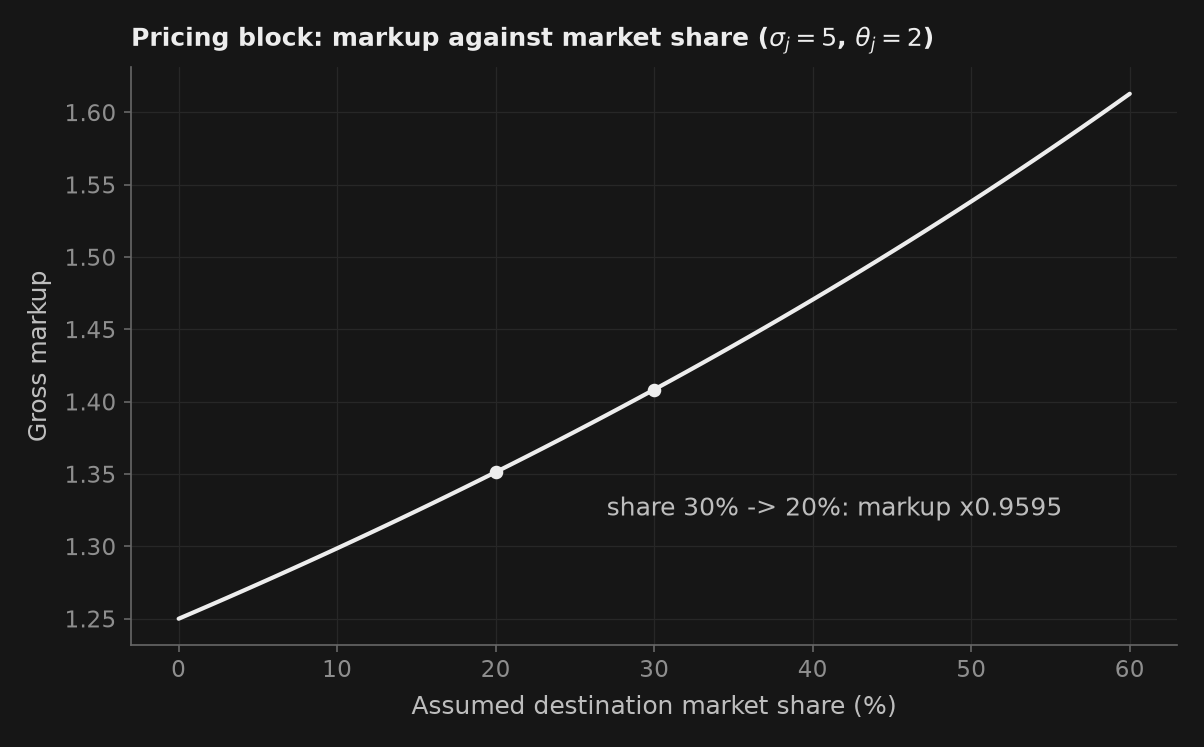

In [4]:
market_shares = np.linspace(0., .6, 61)
sigma_j, theta_j = 5., 2.  # within-sector elasticity above the across-sector one
markups, _ = compute_atkeson_burstein_markups(market_shares, sigma_j=sigma_j, theta_j=theta_j)
np.testing.assert_allclose(markups, sigma_j / (sigma_j - 1 + (1 - sigma_j / theta_j) * market_shares))
assert np.all(np.diff(markups) > 0)  # larger share, less elastic residual demand, higher markup
initial_markup, _ = compute_atkeson_burstein_markups(np.array([.30]), sigma_j=sigma_j, theta_j=theta_j)
# With mu_0 given, the function returns the price at the unchanged marginal cost c_i = 1.
new_markup, relative_price = compute_atkeson_burstein_markups(np.array([.20]),
    c_i=np.ones(1), mu_0=initial_markup, sigma_j=sigma_j, theta_j=theta_j)
markup_ratio = float(new_markup[0] / initial_markup[0])
np.testing.assert_allclose(relative_price, markup_ratio)
print(f"Share 0.30 -> 0.20: markup {initial_markup[0]:.4f} -> {new_markup[0]:.4f}; "
      f"price at unchanged cost x{markup_ratio:.4f} ({100 * (1 - markup_ratio):.2f}% lower)")
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(100 * market_shares, markups, color=colors[0])
ax.plot([30, 20], [initial_markup[0], new_markup[0]], linestyle="none", marker="o", color=colors[0])
ax.annotate(f"share 30% -> 20%: markup x{markup_ratio:.4f}", xy=(25, new_markup[0]),
            xytext=(27, new_markup[0] - .03), color=_nbstyle.TEXTO)
ax.set(xlabel="Assumed destination market share (%)", ylabel="Gross markup",
       title=rf"Pricing block: markup against market share ($\sigma_j={sigma_j:g}$, $\theta_j={theta_j:g}$)")

### 4. Un equilibrio arancelario de referencia

`solve_trade_equilibrium` con contabilidad consistente ([docs/es/trade_accounting.md](../docs/es/trade_accounting.md)): comercio valorado a precios de productor, aranceles devueltos como transferencia de suma fija y ahorro externo fijo en unidades de A-FOOD, el numerario. Cada productor compra insumos de un único nido CES con $\sigma=2$ sobre los cuatro países-sector de origen, de modo que $\sigma$ también gobierna la sustitución entre insumos FOOD y MANU. Las canastas de uso final tienen coeficientes fijos y cada categoría de uso final gasta una fracción fija del ingreso (la inversión, neta del ahorro externo). El país A grava todas sus importaciones desde B con un 10%, para uso intermedio y final. $\sigma=2$ es ilustrativo, no una estimación; la sección 5 lo varía. Este cálculo no usa los bloques de las secciones 1-3.

In [5]:
# Consistent accounting: producer-price trade, duties rebated lump sum, foreign saving fixed in
# units of A-FOOD (the numeraire), one CES nest with elasticity sigma over all origin cells.
ge_options = dict(method="newton", accounting="consistent", sigma=2., tol=1e-8, max_iter=80)


def solve_tariff(sigma, tariff, **extra):
    """Baseline and counterfactual when A taxes all imports from B at the rate `tariff`."""
    options = {**ge_options, "sigma": sigma, **extra}
    rates = np.array([tariff, 0.])  # ad valorem rates by importing country, not multipliers
    start = solve_trade_equilibrium(calib, **options)
    result = solve_trade_equilibrium(calib, tau=rates, tau_fd=rates, base_result=start, **options)
    for solved in (start, result):
        assert solved.converged and solved.max_residual <= options["tol"]
    return start, result


def incidence_on_b(start, result, tariff):
    """Share of A's log tariff absorbed by the fall in B's producer prices (A-FOOD fixed at 1)."""
    return -np.log(result.p_sol[0, :, 1] / start.p_sol[0, :, 1]) / np.log1p(tariff)


tariff = .10
base, counterfactual = solve_tariff(2., tariff)
print(f"Maximum residual: baseline {base.max_residual:.1e}, counterfactual {counterfactual.max_residual:.1e}")
sector_labels = [f"{country}-{sector}" for country in calib.country_codes for sector in calib.sector_codes]
price_changes = 100 * (counterfactual.p_sol / base.p_sol - 1).ravel(order="F")
output_changes = 100 * (counterfactual.y_sol / base.y_sol - 1).ravel(order="F")
print(pd.DataFrame({"producer price (%)": price_changes, "gross output (%)": output_changes},
                   index=sector_labels).round(3).to_string())
incidence = incidence_on_b(base, counterfactual, tariff)
landed = (1 + tariff) * counterfactual.p_sol[0, :, 1] / base.p_sol[0, :, 1]
tot_a, tot_b = counterfactual.terms_of_trade
wage_change = 100 * (counterfactual.w_sol / base.w_sol - 1).ravel()
rent_change = 100 * (counterfactual.r_sol / base.r_sol - 1).ravel()
print("Tariff-inclusive price of B's goods in A (baseline 1): FOOD {:.4f}, MANU {:.4f}".format(*landed))
print("Share of the tariff borne by B's producer prices: FOOD {:.3f}, MANU {:.3f}".format(*incidence))
print(f"Terms of trade (export / import unit value): A {tot_a:.4f}, B {tot_b:.4f}")
print("Wages (%): A {:+.3f}, B {:+.3f}; rental rates (%): A {:+.3f}, B {:+.3f}".format(*wage_change, *rent_change))
assert price_changes[0] == 0  # A-FOOD is the numeraire
# Headline: B bears roughly all of the tariff, and A's terms of trade rise by about 1 + t.
assert np.all((incidence > .9) & (incidence < 1.1)) and abs(np.log(tot_a) / np.log1p(tariff) - 1) < .01
# Closure check: foreign saving fixed as a share of world factor income instead of in A-FOOD units.
world = incidence_on_b(*solve_tariff(2., tariff, foreign_saving_units="world_income"), tariff)
print("Same shares with foreign saving fixed as a share of world income: FOOD {:.3f}, MANU {:.3f}".format(*world))

Maximum residual: baseline 2.8e-14, counterfactual 4.8e-12
        producer price (%)  gross output (%)
A-FOOD               0.000             0.276
A-MANU              -0.023            -0.164
B-FOOD              -8.807            -0.129
B-MANU              -9.269             0.077
Tariff-inclusive price of B's goods in A (baseline 1): FOOD 1.0031, MANU 0.9980
Share of the tariff borne by B's producer prices: FOOD 0.967, MANU 1.021
Terms of trade (export / import unit value): A 1.0999, B 0.9092
Wages (%): A +0.054, B -10.499; rental rates (%): A -0.081, B -10.440
Same shares with foreign saving fixed as a share of world income: FOOD 0.907, MANU 0.957


### 5. Cuánto del arancel soporta B depende de $\sigma$

Repetimos el cálculo con el arancel de 10% sobre una cuadrícula de $\sigma$ y localizamos el $\sigma$ en el que el jacobiano del sistema de equilibrio en la referencia es singular. La cuadrícula omite el intervalo entre 0.8 y 1.2 alrededor de ese punto.

       B-FOOD  B-MANU  A terms of trade
sigma                                  
0.0     0.029   0.028             0.998
0.5    -0.446  -0.473             0.951
0.8    -2.048  -2.163             0.806
1.2     2.951   3.126             1.349
2.0     0.967   1.021             1.100
5.0     0.616   0.648             1.061
det J changes sign at sigma* = 0.9892; Newton at sigma = 1 converged: False


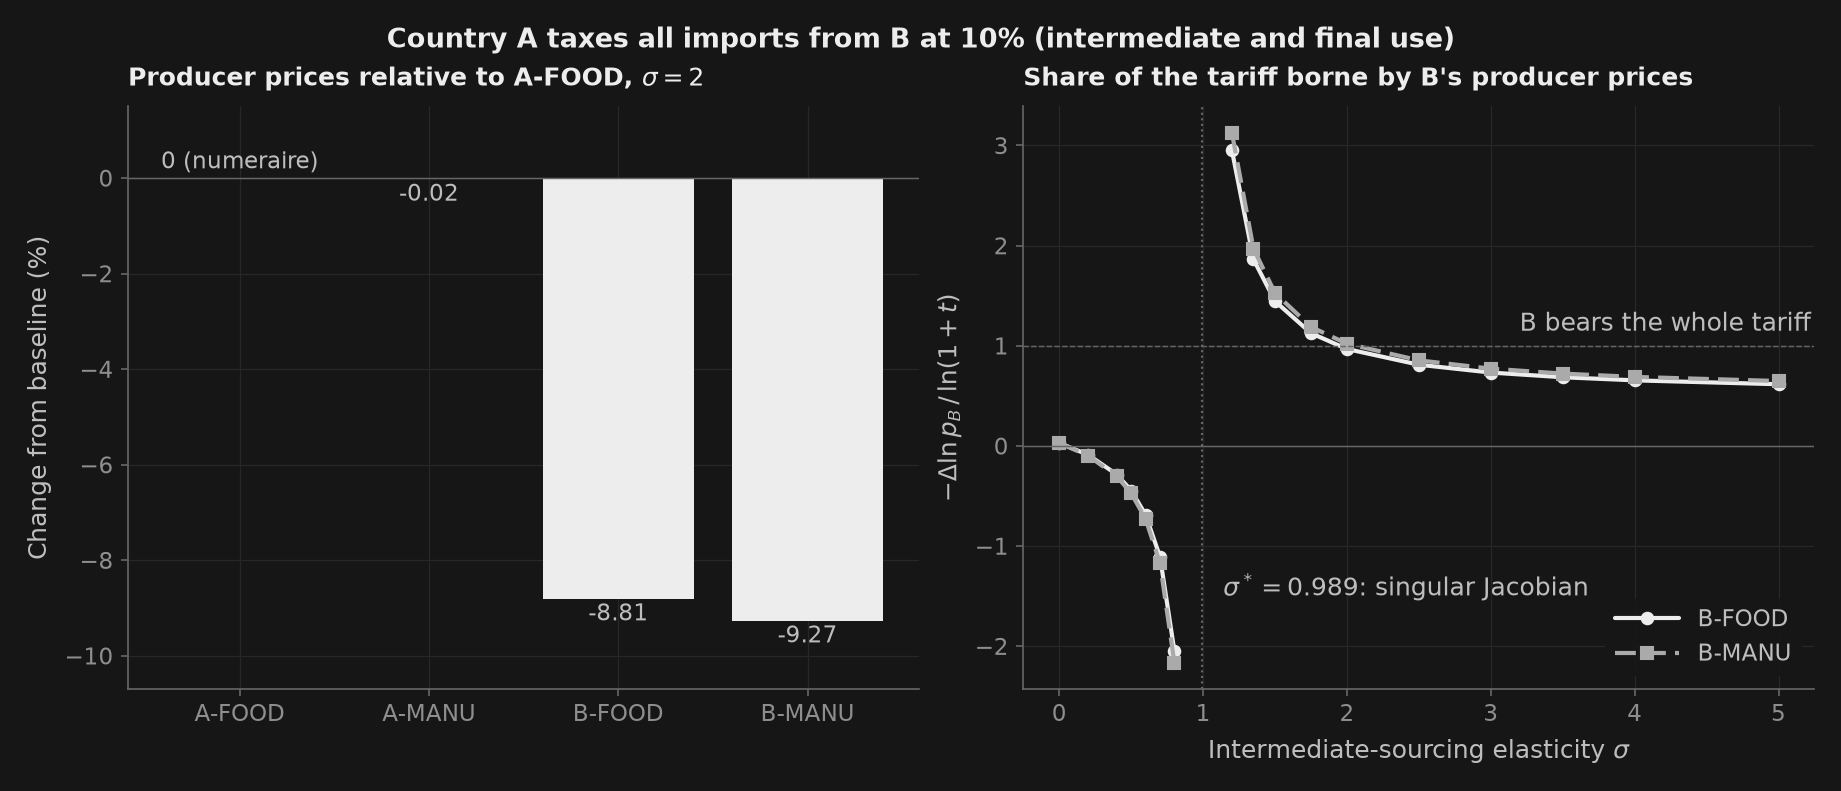

In [6]:
sigma_grid = np.r_[0., .2, .4, .5, .6, .7, .8, 1.2, 1.35, 1.5, 1.75, 2., 2.5, 3., 3.5, 4., 5.]
share_columns = ["B-FOOD", "B-MANU"]
sweep = pd.DataFrame(index=pd.Index(sigma_grid, name="sigma"),
                     columns=[*share_columns, "A terms of trade"], dtype=float)
for sigma in sigma_grid:
    start, result = solve_tariff(sigma, tariff)
    sweep.loc[sigma] = [*incidence_on_b(start, result, tariff), result.terms_of_trade[0]]
print(sweep.loc[[0., .5, .8, 1.2, 2., 5.]].round(3).to_string())

# The benchmark state is the same for every sigma, so the Jacobian there depends on sigma alone.
x0 = base.x_sol.ravel()


def benchmark_jacobian(sigma, h=1e-6):
    residual = lambda x: compute_equilibrium_residuals(x, calib, sigma=sigma, accounting="consistent")
    return np.column_stack([(residual(x0 + h * e) - residual(x0 - h * e)) / (2 * h)
                            for e in np.eye(x0.size)])


sigma_star = brentq(lambda s: np.linalg.det(benchmark_jacobian(s)), .9, 1.05, xtol=1e-6)
# Symptom, not a check: from the benchmark start, Newton does not find the 10% equilibrium near sigma*.
near_options = {**ge_options, "sigma": 1.}
near = solve_trade_equilibrium(calib, tau=np.array([tariff, 0.]), tau_fd=np.array([tariff, 0.]),
                               base_result=solve_trade_equilibrium(calib, **near_options), **near_options)
print(f"det J changes sign at sigma* = {sigma_star:.4f}; Newton at sigma = 1 converged: {near.converged}")
assert np.all(np.abs(sweep.loc[0., share_columns]) < .05)  # nothing substitutes: B's prices barely move
assert np.all(sweep.loc[.5, share_columns] < 0) and np.all(sweep.loc[2., share_columns] > 0)
above = sweep.loc[sweep.index > sigma_star, share_columns].to_numpy()
assert np.all(np.diff(above, axis=0) < 0)  # above sigma*, easier substitution shifts less onto B

fig, (ax_price, ax_share) = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
fig.suptitle(f"Country A taxes all imports from B at {100 * tariff:.0f}% (intermediate and final use)")
ax_price.bar(sector_labels, price_changes, color=colors[0])
ax_price.axhline(0, color=_nbstyle.SPINE, linewidth=.7)
bar_labels = _nbstyle.etiquetar_barras(ax_price, fmt="{:.2f}")
bar_labels[0].set_text("0 (numeraire)")
ax_price.set_ylim(1.1 * price_changes.min() - .5, 1.5)
ax_price.set(title=r"Producer prices relative to A-FOOD, $\sigma=2$", ylabel="Change from baseline (%)")
for column, color, dash, marker in zip(share_columns, colors, dashes, ["o", "s"]):
    for side, label in ((sweep.index < sigma_star, column), (sweep.index > sigma_star, None)):
        ax_share.plot(sweep.index[side], sweep.loc[side, column], color=color, linestyle=dash,
                      marker=marker, label=label)
ax_share.axhline(1, color=_nbstyle.SPINE, linewidth=.7, linestyle="--")
ax_share.axhline(0, color=_nbstyle.SPINE, linewidth=.7)
ax_share.axvline(sigma_star, color=_nbstyle.SPINE, linewidth=1, linestyle=":")
ax_share.annotate("B bears the whole tariff", xy=(3.2, 1), xytext=(3.2, 1.15), color=_nbstyle.TEXTO)
ax_share.annotate(rf"$\sigma^*={sigma_star:.3f}$: singular Jacobian", xy=(sigma_star, -1.5),
                  xytext=(sigma_star + .15, -1.5), color=_nbstyle.TEXTO)
ax_share.set(title="Share of the tariff borne by B's producer prices",
             xlabel=r"Intermediate-sourcing elasticity $\sigma$", ylabel=r"$-\Delta\ln p_B\,/\,\ln(1+t)$")
ax_share.legend(loc="lower right")

### 6. Los bloques flexibles en equilibrio general, por dos vías

`solve_flexible_trade_equilibrium` lleva los bloques de las secciones 1-3 al equilibrio general con la misma contabilidad consistente de la sección 4. Para los bloques de tecnología ($\rho_{va}$, $\sigma_{inter}$), `solve_ces_block_newton` resuelve el mismo CES anidado con otro algoritmo: Newton exacto por bloques sobre precios y cantidades, mientras que el solucionador flexible aplica un Newton condensado sobre precios de factores y transferencias. Resolver el arancel de 10% por ambas vías, con $\sigma_{inter}=2$ como en la sección 4, contrasta una vía con la otra y muestra cuánto importa $\rho_{va}$. La tabla reporta cada precio de B relativo a A-FOOD. Ambas vías son código de puremacro, así que su coincidencia comprueba la implementación, no el modelo.

In [7]:
def relative_to_a_food(result, baseline):
    """Percent change of each producer price relative to A-FOOD."""
    ratio = (result.p_sol / baseline.p_sol).ravel(order="F")
    return 100 * (ratio / ratio[0] - 1)


no_tariff, a_tariff = np.zeros(2), np.array([tariff, 0.])
routes = {}
for rho_va in (.5, 1., 2.):
    # Route 1: the nested-CES technology solved by exact block Newton.
    technology = NestedCESTechnology.from_flexible(FlexibleTechnologyConfig(rho_va=rho_va, sigma_inter=2.))
    block = [solve_ces_block_newton(calib, r, r, technology=technology).equilibrium
             for r in (no_tariff, a_tariff)]
    # Route 2: the flexible solver (condensed Newton on factor prices and transfers).
    flexible = [solve_flexible_trade_equilibrium(calib, rho_va=rho_va, sigma_inter=2., tau=r, tau_fd=r, tol=1e-10)
                for r in (no_tariff, a_tariff)]
    assert all(solved.converged for solved in block + flexible)
    assert flexible[1].metadata["flexible_settings_applied"]
    routes[f"rho_va = {rho_va:.1f}"] = [*relative_to_a_food(block[1], block[0])[2:],
                                        *relative_to_a_food(flexible[1], flexible[0])[2:]]
routes = pd.DataFrame(routes, index=["block Newton B-FOOD", "block Newton B-MANU",
                                     "flexible B-FOOD", "flexible B-MANU"]).T
print("Change in B's producer prices relative to A-FOOD (%), sigma_inter = 2:")
print(routes.round(3).to_string())
route_gap = np.abs(routes.iloc[:, :2].to_numpy() - routes.iloc[:, 2:].to_numpy()).max()
print(f"Largest gap between the two routes (percentage points): {route_gap:.1e}")
assert route_gap < 1e-6
# At rho_va = 1 the nested CES is section 4's technology, so both routes reproduce its prices.
np.testing.assert_allclose(routes.iloc[1, :2], price_changes[2:], atol=1e-6)
np.testing.assert_allclose(routes.iloc[1, 2:], price_changes[2:], atol=1e-6)
# rho_va moves each price by a small fraction of the tariff's effect.
rho_spread = (routes.max() - routes.min()).max()
print(f"Largest change of any column across rho_va (percentage points): {rho_spread:.3f}")
assert (routes < 0).all().all() and rho_spread < .1
# With Leontief sourcing (sigma_inter = 0) rho_va has no effect at all on this economy.
leontief = {}
for rho_va in (.5, 2.):
    baseline, shocked = [solve_flexible_trade_equilibrium(calib, rho_va=rho_va, tau=r, tau_fd=r, tol=1e-10)
                         for r in (no_tariff, a_tariff)]
    # The output mix cannot change, so w/r stays at its baseline and rho_va never comes into play.
    assert np.abs(np.log((shocked.w_sol / shocked.r_sol) / (baseline.w_sol / baseline.r_sol))).max() < 1e-10
    leontief[rho_va] = relative_to_a_food(shocked, baseline)
np.testing.assert_allclose(leontief[.5], leontief[2.], atol=1e-8)
print("sigma_inter = 0, B's prices relative to A-FOOD (%), identical for rho_va = 0.5 and 2:",
      np.round(leontief[.5][2:], 3))

Change in B's producer prices relative to A-FOOD (%), sigma_inter = 2:
              block Newton B-FOOD  block Newton B-MANU  flexible B-FOOD  flexible B-MANU
rho_va = 0.5               -8.830               -9.281           -8.830           -9.281
rho_va = 1.0               -8.807               -9.269           -8.807           -9.269
rho_va = 2.0               -8.796               -9.262           -8.796           -9.262
Largest gap between the two routes (percentage points): 2.1e-10
Largest change of any column across rho_va (percentage points): 0.034
sigma_inter = 0, B's prices relative to A-FOOD (%), identical for rho_va = 0.5 and 2: [-0.273 -0.264]


## Lectura de los resultados

**Bloques a precios dados.** En la primera figura el capital por trabajador en las manufacturas de A sigue exactamente $(w/r)^\rho$: cuando el salario sube 20% frente a la renta del capital, llega a 1.136, 1.200 y 1.291 veces su valor de referencia para $\rho=0.7$, 1.0 y 1.4. En la segunda, la subsistencia convierte a los alimentos en un bien necesario: la participación de los alimentos en A cae de 45.3% con 0.6 veces el presupuesto de referencia a 36.9% con 1.8 veces, frente a un 40.5% constante sin subsistencia. El gasto de subsistencia se mantiene entre 0.068 y 0.193 del presupuesto en la cuadrícula (0.366 en el límite de presupuesto nulo), porque $\gamma s_0=0.121$ está por debajo de $\tanh(3)/3=0.332$; el recorte nunca se activa. En la tercera, una caída de la participación de mercado de 0.30 a 0.20 reduce el margen de 1.4085 a 1.3514, un precio 4.05% menor con el costo marginal sin cambio.

**Quién soporta el arancel de A.** Con $\sigma=2$, los precios de productor de B caen 8.807% (FOOD) y 9.269% (MANU) relativos a A-FOOD, mientras que A-MANU se mueve -0.023% y ninguna producción bruta cambia más de 0.276%. B absorbe 0.967 y 1.021 del arancel en logaritmos, así que el precio con arancel de los bienes de B en A casi no cambia (1.0031 para FOOD, 0.9980 para MANU). El ajuste ocurre por los términos de intercambio: los de A suben a 1.0999, casi exactamente $1+t$, y los de B caen a 0.9092. El salario de B cae 10.499% y su renta del capital 10.440%, mientras que los precios de los factores de A se mueven menos de una décima de punto porcentual. Para B-MANU el precio en A incluso cae por debajo de su nivel previo al arancel, un resultado de tipo Metzler (1949) para ese bien. Esta incidencia casi completa pertenece a este cierre y a esta calibración: con el ahorro externo fijo como fracción del ingreso mundial, que elimina la dependencia de qué país se lista primero, B absorbe 0.907 y 0.957.

**La elección de $\sigma$.** $\sigma=2$ es ilustrativo, y la respuesta depende mucho de él. Con $\sigma=0$ nada se sustituye y B absorbe solo 0.029 y 0.028. Por encima del punto singular la participación cae cuando $\sigma$ sube, hasta 0.616 y 0.648 con $\sigma=5$. El jacobiano en la referencia es singular en $\sigma^*=0.9892$, donde su determinante cambia de signo. La respuesta a un arancel pequeño es $-J^{-1}\partial R/\partial t$, que no está acotada en $\sigma^*$ y cambia de signo al cruzarlo: la participación de B es 2.951 y 3.126 con $\sigma=1.2$, pero -2.048 y -2.163 con $\sigma=0.8$. Con $\sigma=0.5$ los precios de B suben (participaciones -0.446 y -0.473) y los términos de intercambio de A caen a 0.951, como anticipa el razonamiento de tipo Marshall-Lerner de la intuición. Cerca de $\sigma^*$, Newton desde la referencia no encuentra el equilibrio con 10% (con $\sigma=1$ reporta `converged: False`).

**Los bloques flexibles en equilibrio.** Las dos vías coinciden con una diferencia de a lo sumo 2.1e-10 puntos porcentuales, y con $\rho_{va}=1$ ambas reproducen los precios de la sección 4. Con $\sigma_{inter}=2$, el arancel baja los precios de B relativos a A-FOOD entre 8.796% y 8.830% (FOOD) y entre 9.262% y 9.281% (MANU) cuando $\rho_{va}$ va de 2 a 0.5: cambiar $\rho_{va}$ mueve cualquiera de estos precios como mucho 0.034 puntos porcentuales. Con abastecimiento Leontief ($\sigma_{inter}=0$) no tiene ningún efecto: los dos sectores de un país venden a cada uso final en las mismas proporciones, así que la composición de la producción de un país y su $w/r$ no pueden cambiar, y $\rho_{va}$ nunca interviene (los precios de B caen 0.273% y 0.264% con cualquier $\rho_{va}$). En esta economía la elasticidad de abastecimiento intermedio decide cuánto del arancel soporta B; el bloque de sustitución de factores apenas importa. Ninguna de estas cifras es una medida de bienestar, y la convergencia del modelo de referencia no establece bienestar hicksiano ni identifica un efecto causal del arancel.

## Tu turno

Elija la elasticidad de abastecimiento y el arancel de A. La celda reporta la parte del arancel que soportan los precios de productor de B junto al cálculo con $\sigma=2$ y el mismo arancel y al cálculo con 10% y el mismo $\sigma$, y comprueba dos predicciones.

In [8]:
custom_sigma = 5.  # ← change this: sourcing elasticity sigma, advertised range 1.5 to 10
custom_tariff = .15  # ← change this: A's tariff rate, advertised range 0.05 to 0.30
assert 1.5 <= custom_sigma <= 10 and .05 <= custom_tariff <= .30
start, result = solve_tariff(custom_sigma, custom_tariff)
custom = incidence_on_b(start, result, custom_tariff)
at_sigma_2 = incidence_on_b(*solve_tariff(2., custom_tariff), custom_tariff)
at_10_percent = incidence_on_b(*solve_tariff(custom_sigma, .10), .10)
print(pd.DataFrame({f"sigma={custom_sigma:g}, t={custom_tariff:.2f}": custom,
                    f"sigma=2, t={custom_tariff:.2f}": at_sigma_2,
                    f"sigma={custom_sigma:g}, t=0.10": at_10_percent},
                   index=share_columns).round(3).to_string())
print(f"A's terms of trade: {result.terms_of_trade[0]:.4f}")
# A gains through its terms of trade and B's prices fall (true only above sigma*), and B bears
# less of the tariff the more easily A's producers switch suppliers.
assert result.terms_of_trade[0] > 1 and np.all(custom > 0)
assert np.all((custom < at_sigma_2) == (custom_sigma > 2))

        sigma=5, t=0.15  sigma=2, t=0.15  sigma=5, t=0.10
B-FOOD            0.620            0.976            0.616
B-MANU            0.652            1.030            0.648
A's terms of trade: 1.0911


1. *Básico.* Antes de ejecutar, prediga si B soporta más o menos de un arancel de 15% con $\sigma=5$ que con $\sigma=2$, y explíquelo con el precio con arancel de los bienes de B en A. Luego mueva `custom_tariff` dentro de su rango: ¿depende mucho la parte de B del tamaño del arancel? ¿Por qué el rango de `custom_sigma` empieza por encima de $\sigma^*$, y cuál de los dos asserts económicos falla con $\sigma=0.8$ si se quita la comprobación del rango?
2. *Intermedio.* Elasticidad de la demanda de trabajo respecto del propio salario en el CES anidado. Como en el experimento 1, mantenga fijos la producción, las rentas del capital y los precios de los insumos, mueva todos los salarios $\pm h$ en logaritmos ($h=10^{-6}$) y calcule $\varepsilon=d\ln L/d\ln w$ para $(\rho,\sigma_y)$ en {(1.4, 0), (1.4, 0.2), (1.4, 1), (0.5, 2)}. Derive primero la respuesta: con $L\propto y\,(c_Y/c_{VA})^{\sigma_y}(c_{VA}/w)^{\rho}$, $d\ln c_{VA}/d\ln w=1-\alpha$ y $d\ln c_Y/d\ln w=(1-\theta_M)(1-\alpha)$, muestre que $\varepsilon=-[\alpha\rho+\sigma_y\theta_M(1-\alpha)]$, donde `theta_M = calib.a.sum(axis=0)[None] / (1 - calib.tax)` es la participación de los insumos en el costo y `calib.alpha` es $\alpha$. Compruébelo con `np.testing.assert_allclose(eps, -(calib.alpha * rho + sigma_y * theta_M * (1 - calib.alpha)), rtol=1e-6)`. ¿Por qué la elasticidad es $\alpha\rho$ y no $\rho$ cuando $\sigma_y=0$?
3. *Avanzado.* ¿Cuándo rompe el presupuesto la regla de subsistencia suave? Para el país A a precios unitarios, con participación de subsistencia de alimentos $\gamma$: (a) con `compute_les_marginal_budget_shares` para $b$, muestre que la participación de los alimentos en el presupuesto es $b+(1-b)\gamma s_0 g(u)/u$ mientras el ingreso supernumerario no sea negativo, y compruébelo para $\gamma$ en {0.3, 0.9} en `np.linspace(.2, 1.8, 17)`. (b) Un LES de libro de texto con un piso fijo $\gamma c_{0}$ se queda sin ingreso supernumerario en $u=\gamma s_0$; la regla suave, solo donde $u<\gamma s_0 g(u)$. Use $g(u)/u\le 3/\tanh 3$ para derivar el umbral $\gamma^*=\tanh(3)/(3s_0)$ por debajo del cual el presupuesto se cumple a cualquier ingreso; compruebe `assert .8 < gamma_star < .85`. (c) Para $\gamma=0.9$, encuentre la raíz $u_r$ de $u=\gamma s_0 g(u)$ con `brentq` y muestre que el gasto excesivo relativo es cero en $1.02\,u_r$ y mayor que $10^{-3}$ en $0.98\,u_r$, donde la biblioteca emite una advertencia. Explique por qué un piso que depende del ingreso deja esta demanda sin función de gasto.

## ¿Qué tan exhaustivo es esto?

El cuaderno evalúa tres bloques flexibles a precios dados y resuelve un pequeño equilibrio de referencia con contabilidad consistente. `solve_flexible_trade_equilibrium` combina todos los bloques (además de penalizaciones de capacidad y abastecimiento Armington de la demanda final mediante `sigma_trade`) en equilibrio general con contabilidad consistente; con ajustes activos, las calibraciones de más de 100 celdas país-sector requieren `method="quasi_condensed"` (Newton denso) o lanzan `ValueError`. [docs/es/trade_accounting.md](../docs/es/trade_accounting.md) define el cierre consistente; [docs/es/trade_ces_newton.md](../docs/es/trade_ces_newton.md) documenta `solve_ces_block_newton`, una segunda vía por código de puremacro y no un oráculo independiente; `puremacro.trade.household` ([docs/es/trade_household.md](../docs/es/trade_household.md)) contiene el hogar Stone-Geary exacto con piso fijo y función de gasto. El cuaderno 63 calcula el bienestar hicksiano del consumo y el 65 separa la propagación de costos, la contabilidad y las comprobaciones de bienestar. Para datos insumo-producto reales use `load_oecd_icio_granular` o `puremacro.trade.mrio.read_oecd_native`.